# Huấn luyện CatBoost dự đoán năng suất lúa — phương án B

Thay quy trình 7 mô hình và Stacking thủ công bằng **một CatBoostRegressor**, với hai dự báo đơn giản làm mốc so sánh. Giữ tên file notebook để tiếp tục đồ án hiện tại.

- Bộ dữ liệu nhỏ: 579 bản ghi tỉnh–năm–nhóm vụ; huấn luyện CPU, tìm kiếm có giới hạn 12 cấu hình.
- CatBoost nhận trực tiếp đặc trưng số và phân loại; không chuẩn hóa, không One-Hot thủ công, không điền trung vị từ toàn bộ CSV.
- Chia theo năm: Train 2000–2015 → Validation 2016–2018 → Test 2019–2022. Validation phục vụ chọn cấu hình và dừng sớm; chỉ Test là đánh giá cuối cùng chưa dùng khi lựa chọn.
- Pearson/Spearman chỉ phân tích trên Train. Không loại biến chỉ vì |PCC| thấp: mô hình cây có thể sử dụng quan hệ phi tuyến và tương tác.
- Dùng CatBoost trực tiếp thay cho lớp bọc PyCaret để dễ kiểm soát tập đánh giá và số vòng lặp; không dùng K-Fold ngẫu nhiên.

**Cách chạy:** chọn kernel có thư viện trong `requirements-training.txt` (cùng thư mục notebook), rồi Restart Kernel → Run All. Từ thư mục gốc dự án có thể cài bằng `python -m pip install -r notebook/requirements-training.txt`.

## Kiểm tra tính hợp lý và nguồn tham khảo

Cả A và B đều là ứng viên hợp lý; chưa thể khẳng định A tối ưu nhất trước khi so sánh trên cùng dữ liệu và cách chia tập.

- [Huo et al., 2026](https://www.frontiersin.org/journals/plant-science/articles/10.3389/fpls.2026.1866530/full): bài khớp mô tả PCC–AutoGluon xuất bản 08/07/2026, không phải 2024. Bài báo ghi R² = 0.736 so với trung bình mô hình đơn 0.649, tức tăng khoảng 13% **tương đối**, hay 0.087 R²; đây là dữ liệu UAV tại Trung Quốc, không phải bảo đảm cho CSV này.
- [De Clercq & Mahdi, 2024](https://arxiv.org/abs/2403.07967): nghiên cứu trên 247 huyện của Ấn Độ báo cáo R² ngoài mẫu lên đến 0.82; kết quả đó không phải ngưỡng bắt buộc cho dữ liệu tỉnh ở ĐBSCL.
- [AutoGluon TabularPredictor.fit](https://auto.gluon.ai/stable/api/autogluon.tabular.TabularPredictor.fit.html): bagging/stacking phụ thuộc preset và các tham số, không tự bảo đảm chỉ bằng nạp CSV. Phải cấu hình kiểm định theo thời gian cho bài toán dự đoán năm tương lai.
- [CatBoost: biến phân loại](https://catboost.ai/docs/en/features/categorical-features), [giá trị thiếu](https://catboost.ai/docs/en/concepts/algorithm-missing-values-processing): hỗ trợ phân loại và NaN của biến số. Biến phân loại thiếu được thay bằng chuỗi cố định. Mô hình cây không đòi hỏi loại đa cộng tuyến như hồi quy tuyến tính, nhưng các biến tương quan vẫn có thể làm độ quan trọng đặc trưng kém ổn định.

## Phạm vi sử dụng dữ liệu

Mục tiêu là **ước lượng hồi cứu năng suất theo tỉnh và nhóm vụ sau khi có đủ dữ liệu của cửa sổ quan sát**, chưa phải dự báo trước thu hoạch. Các tỉnh có mặt trong Train tiếp tục xuất hiện ở Validation/Test; kết quả không đo khả năng chuyển sang tỉnh mới.

Mã GEE hiện tại (`src/code_gee/gee_rice_ndvi_evi_vci_2000_2022.js`) dùng:

- **VCI chuẩn 2000–2015**, chỉ thuộc giai đoạn Train của phép chia chính. Giữ nguyên chuẩn khi đánh giá 2016–2022; không tái chuẩn hóa bằng Validation/Test. Không dùng VCI này để tuyên bố kiểm định tiến theo thời gian bên trong các năm trước 2015, vì mốc chuẩn đã bao gồm dữ liệu sau các năm ấy.
- **Mặt nạ lúa 2020**, áp dụng cho cả lịch sử. Đây là thông tin tương lai đối với nhiều năm đánh giá. Chia tập theo thời gian không xóa được giới hạn của dữ liệu đầu vào này. Muốn đánh giá dự báo vận hành nghiêm ngặt, phải xuất lại dữ liệu với mặt nạ có sẵn trước thời điểm dự báo và cửa sổ đúng thời hạn.
- Cửa sổ vụ là đại diện: đông xuân tháng 11–4, hè thu–thu đông tháng 4–11; nhóm vụ gộp có sai khác giữa địa phương. Năm 2000 thiếu vệ tinh đầu cửa sổ; giữ biến chất lượng để mô tả mức phủ dữ liệu.

Notebook sửa cách tiền xử lý và huấn luyện; không thay đổi CSV gốc hoặc tự tạo lại chỉ số vệ tinh.

## 1. Thư viện và cấu hình cố định trước khi đánh giá Test

In [1]:
from pathlib import Path
from itertools import product
from time import perf_counter
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import catboost
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

RANDOM_STATE = 42
THREAD_COUNT = 4
MAX_ITERATIONS = 1500
EARLY_STOPPING_ROUNDS = 100
# Định nghĩa trước: 3 độ sâu × 2 tốc độ học × 2 mức regularization.
SEARCH_CONFIGS = [dict(depth=d, learning_rate=lr, l2_leaf_reg=l2)
                  for d, lr, l2 in product([4, 5, 6], [0.03, 0.06], [3.0, 10.0])]
SORT_KEYS = ['nam', 'mua_vu', 'adm1_code']
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True,
                     'grid.alpha': 0.22, 'font.size': 10})
print(f'CatBoost {catboost.__version__}; {len(SEARCH_CONFIGS)} cấu hình; CPU {THREAD_COUNT} luồng.')

CatBoost 1.2.8; 12 cấu hình; CPU 4 luồng.


## 2. Đường dẫn đầu vào và thư mục kết quả riêng cho CatBoost

In [2]:
DATA_FILENAME = 'rice_ml_features_2000_2022.csv'
folders = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((folder for folder in folders
    if (folder / 'data' / 'processed' / DATA_FILENAME).is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Hãy chạy kernel từ thư mục dự án hoặc notebook/ có CSV trong data/processed/.')
DATA_FILE = PROJECT_ROOT / 'data' / 'processed' / DATA_FILENAME
REPORTS_DIR = PROJECT_ROOT / 'reports' / 'catboost'
FIGURES_DIR = REPORTS_DIR / 'figures'
MODELS_DIR = PROJECT_ROOT / 'models' / 'catboost'
for folder in [REPORTS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIGURES_DIR / name, dpi=160, bbox_inches='tight')

print('CSV:', DATA_FILE)
print('Báo cáo:', REPORTS_DIR)
print('Mô hình:', MODELS_DIR)

CSV: /workspace/rice_yield_estimation/data/processed/rice_ml_features_2000_2022.csv
Báo cáo: /workspace/rice_yield_estimation/reports/catboost
Mô hình: /workspace/rice_yield_estimation/models/catboost


## Đọc và hiển thị bảng CSV đầu vào
Bảng gồm 24 cột:
- **adm1_code**:            Mã định danh tỉnh theo GAUL 2015.
- **tinh_thanh**:           Tên tỉnh/thành phố.
- **nam**:                  Năm thống kê năng suất lúa.
- **mua_vu**:               Nhóm mùa vụ: dong_xuan hoặc he_thu-thu_dong.
- **nang_suat_t_ha**:	    Năng suất lúa (tấn/ha) — biến mục tiêu cần dự đoán.
- **window_start**:         Tháng bắt đầu khoảng thời gian lấy dữ liệu môi trường.
- **window_end**:           Tháng kết thúc khoảng thời gian lấy dữ liệu môi trường.
- **window_months**:        Tổng số tháng trong khoảng thời gian quan sát.
- **temperature_mean_c**:   Nhiệt độ trung bình trong khoảng quan sát (°C).
- **temperature_min_c**:    Nhiệt độ trung bình tháng thấp nhất trong khoảng quan sát (°C).
- **temperature_max_c**:    Nhiệt độ trung bình tháng cao nhất trong khoảng quan sát (°C).
- **rainfall_sum_mm**:      Tổng lượng mưa trong khoảng quan sát (mm).
- **rainfall_max_month_mm**:Lượng mưa của tháng mưa nhiều nhất (mm).
- **rainy_months_100mm**:   Số tháng có lượng mưa từ 100 mm trở lên.
- **ndvi_mean**:            Giá trị NDVI trung bình trong khoảng quan sát, phản ánh mức độ xanh của thảm thực vật vùng lúa.
- **ndvi_max**:             Giá trị NDVI cao nhất trong khoảng quan sát.
- **evi_mean**:             Giá trị EVI trung bình trong khoảng quan sát, phản ánh tình trạng thảm thực vật và tán lá.
- **evi_max**:              Giá trị EVI cao nhất trong khoảng quan sát.
- **vci_mean**:             Giá trị VCI trung bình trong khoảng quan sát, phản ánh tình trạng thực vật so với mức biến động lịch sử.
- **vci_min**:              Giá trị VCI thấp nhất trong khoảng quan sát.
- **vi_months_available**:  Số tháng có dữ liệu chỉ số thực vật hợp lệ.
- **vi_months_quality80**:  Số tháng có độ phủ pixel vệ tinh đạt ít nhất 80%.
- **vi_quality80_ratio**:   Tỷ lệ số tháng đạt độ phủ ≥80% trên tổng số tháng trong cửa sổ quan sát (0–1).
- **vi_mean_coverage_pct**: Tỷ lệ pixel vệ tinh hợp lệ trung bình của các tháng có dữ liệu (%).

## 3. Đọc CSV, kiểm tra dữ liệu và hợp đồng đặc trưng

Chỉ các cột trong danh sách FEATURES được vào mô hình. `tinh_thanh` dùng cho báo cáo; `adm1_code` được coi là phân loại, không phải đại lượng số. Không đưa nhãn, chuỗi ngày hoặc các cột định danh dư thừa vào mô hình.

Chuẩn hóa kiểu dữ liệu là phép biến đổi cố định, không học từ Validation/Test. NaN của biến số được giữ để CatBoost xử lý nội bộ; giá trị vô cực, nhãn thiếu và khóa trùng sẽ gây lỗi rõ ràng.

In [3]:
TARGET = 'nang_suat_t_ha'
NUMERIC_FEATURES = [
    'nam', 'temperature_mean_c', 'temperature_min_c', 'temperature_max_c',
    'rainfall_sum_mm', 'rainfall_max_month_mm', 'rainy_months_100mm',
    'ndvi_mean', 'ndvi_max', 'evi_mean', 'evi_max', 'vci_mean', 'vci_min',
    'vi_months_available', 'vi_months_quality80', 'vi_quality80_ratio',
    'vi_mean_coverage_pct',
]
CATEGORICAL_FEATURES = ['adm1_code', 'mua_vu']
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
PREPROCESSING = {
    'numeric_features': NUMERIC_FEATURES,
    'categorical_features': CATEGORICAL_FEATURES,
    'categorical_missing_token': '__MISSING__',
    'numeric_missing': 'native_catboost_nan_mode_Min',
    'scaling': None,
    'manual_one_hot': False,
}

def prepare_features(frame, features=FEATURES, schema=PREPROCESSING):
    # Dùng lại đúng hàm và schema này khi suy luận; không fit thống kê trên đầu vào.
    missing_cols = set(features) - set(frame.columns)
    if missing_cols:
        raise ValueError(f'Thiếu đặc trưng: {sorted(missing_cols)}')
    result = frame.loc[:, features].copy()
    for col in schema['numeric_features']:
        result[col] = pd.to_numeric(result[col], errors='raise').astype(float)
        if np.isinf(result[col].to_numpy()).any():
            raise ValueError(f'{col} chứa giá trị vô cực.')
    for col in schema['categorical_features']:
        values = result[col]
        if col == 'adm1_code':
            # 3326, 3326.0 và "3326" phải có cùng biểu diễn khi đọc CSV mới.
            numeric = pd.to_numeric(values, errors='raise')
            observed = numeric.dropna().to_numpy(dtype=float)
            if not np.isfinite(observed).all() or (observed % 1 != 0).any():
                raise ValueError('adm1_code phải là mã nguyên hoặc thiếu.')
            values = numeric.astype('Int64').astype('string')
        else:
            values = values.astype('string').str.strip().replace('', pd.NA)
        result[col] = values.fillna(schema['categorical_missing_token']).astype(str)
    return result

df = pd.read_csv(DATA_FILE, encoding='utf-8-sig')
required = set(FEATURES + [TARGET, 'tinh_thanh', 'window_start', 'window_end'])
if not required.issubset(df.columns):
    raise ValueError(f'Thiếu cột: {sorted(required - set(df.columns))}')
if len(df) != 579:
    raise ValueError(f'CSV hiện tại dự kiến 579 dòng, nhận {len(df)}; kiểm tra lại trước khi đổi mốc chia.')
if df[['adm1_code', 'nam', 'mua_vu']].isna().any().any():
    raise ValueError('Khóa tỉnh–năm–vụ không được thiếu.')
if df.duplicated(['adm1_code', 'nam', 'mua_vu']).any():
    raise ValueError('Trùng tỉnh–năm–nhóm vụ.')
years = pd.to_numeric(df['nam'], errors='raise')
if not np.isfinite(years).all() or (years % 1 != 0).any():
    raise ValueError('Năm phải là số nguyên hữu hạn.')
df['nam'] = years.astype(int)
df[TARGET] = pd.to_numeric(df[TARGET], errors='raise')
if not np.isfinite(df[TARGET]).all() or (df[TARGET] <= 0).any():
    raise ValueError('Nhãn phải là năng suất dương, hữu hạn, không thiếu.')
prepared = prepare_features(df)
for col in FEATURES:
    if col != 'nam':
        df[col] = prepared[col]
if df.duplicated(['adm1_code', 'nam', 'mua_vu']).any():
    raise ValueError('Trùng khóa sau khi chuẩn hóa kiểu dữ liệu.')
df = df.sort_values(SORT_KEYS, kind='stable').reset_index(drop=True)
print(f'Đầu vào: {df.shape[0]} dòng × {df.shape[1]} cột; {len(FEATURES)} đặc trưng.')
display(df.head(10))

Đầu vào: 579 dòng × 24 cột; 19 đặc trưng.


,adm1_code,tinh_thanh,nam,mua_vu,nang_suat_t_ha,window_start,window_end,window_months,temperature_mean_c,temperature_min_c,temperature_max_c,rainfall_sum_mm,rainfall_max_month_mm,rainy_months_100mm,ndvi_mean,ndvi_max,evi_mean,evi_max,vci_mean,vci_min,vi_months_available,vi_months_quality80,vi_quality80_ratio,vi_mean_coverage_pct
0,3326,An Giang,2000,dong_xuan,6.102087,1999-11,2000-04,6,26.466908,24.330084,27.914765,545.048294,214.227481,3.0,0.724219,0.744950,0.569938,0.593500,72.977768,71.174059,3.0,2.0,0.333333,96.889450
1,3330,Bạc Liêu,2000,dong_xuan,4.203488,1999-11,2000-04,6,26.106606,24.316530,27.404704,414.761425,217.156484,1.0,0.387330,0.388726,0.276310,0.282784,19.819480,13.099415,3.0,2.0,0.333333,87.388850
2,3332,Bến Tre,2000,dong_xuan,4.849138,1999-11,2000-04,6,26.128369,24.343505,27.493628,276.675692,165.433183,1.0,NaN,NaN,NaN,NaN,NaN,NaN,3.0,0.0,0.000000,NaN
3,3339,Cà Mau,2000,dong_xuan,3.673333,1999-11,2000-04,6,26.133275,24.374156,27.374585,452.618200,191.914331,1.0,0.505844,0.517804,0.323351,0.339427,41.888396,24.910899,3.0,2.0,0.333333,91.716650
4,3343,Đồng Tháp,2000,dong_xuan,5.872852,1999-11,2000-04,6,26.616159,24.464337,28.148798,459.503678,195.319909,2.0,0.771641,0.853655,0.619410,0.705865,83.286998,75.197259,3.0,3.0,0.500000,90.507333
5,3356,Kiên Giang,2000,dong_xuan,4.957868,1999-11,2000-04,6,26.260207,24.326433,27.515873,592.136468,219.210760,3.0,0.634197,0.659535,0.428023,0.455187,58.704145,52.753716,3.0,2.0,0.333333,86.593000
6,3362,Long An,2000,dong_xuan,4.282805,1999-11,2000-04,6,26.649697,24.534789,28.031708,412.650896,167.884797,2.0,0.698989,0.768495,0.513735,0.588634,68.060624,59.228866,3.0,3.0,0.500000,93.310767
7,3377,Sóc Trăng,2000,dong_xuan,4.853030,1999-11,2000-04,6,26.032478,24.226744,27.416560,370.673717,206.529712,1.0,0.424790,0.435374,0.293549,0.297140,19.483796,11.417289,3.0,2.0,0.333333,91.361700
8,3384,Tiền Giang,2000,dong_xuan,5.680042,1999-11,2000-04,6,26.310698,24.368956,27.653971,312.388203,156.160832,1.0,0.615985,0.647512,0.426166,0.450503,35.100532,17.200200,3.0,2.0,0.333333,94.509650
9,3386,Trà Vinh,2000,dong_xuan,4.941509,1999-11,2000-04,6,26.081292,24.332235,27.475542,292.189090,183.762362,1.0,0.429977,0.445174,0.298825,0.304503,20.742048,10.455387,3.0,2.0,0.333333,92.325150


## 4. Chia Train / Validation / Test theo năm

Giữ nguyên tất cả tỉnh và vụ cùng năm trong cùng một tập. Không xáo trộn dòng, không dùng Test cho chọn biến, siêu tham số hay dừng sớm. `has_time=True` của CatBoost tôn trọng thứ tự dữ liệu đã sắp theo năm khi tạo thống kê phân loại trong huấn luyện; tùy chọn này không thay thế việc chia theo năm.

Train: 399 dòng; Validation: 76 dòng; Test: 104 dòng. Đặc trưng môi trường phải có sẵn tới cuối cửa sổ của bản ghi mới dùng được cho suy luận.

In [4]:
train_df = df.loc[df['nam'].between(2000, 2015)].copy().reset_index(drop=True)
val_df = df.loc[df['nam'].between(2016, 2018)].copy().reset_index(drop=True)
test_df = df.loc[df['nam'].between(2019, 2022)].copy().reset_index(drop=True)
assert (len(train_df), len(val_df), len(test_df)) == (399, 76, 104)
assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert train_df['nam'].max() < val_df['nam'].min()
assert val_df['nam'].max() < test_df['nam'].min()
trainval_df = pd.concat([train_df, val_df], ignore_index=True).sort_values(SORT_KEYS, kind='stable')
X_train, y_train = prepare_features(train_df), train_df[TARGET]
X_val, y_val = prepare_features(val_df), val_df[TARGET]
X_trainval, y_trainval = prepare_features(trainval_df), trainval_df[TARGET]
# X_test/y_test chỉ tạo ở bước đánh giá cuối cùng.
split_summary = pd.DataFrame([
    {'split': name, 'year_min': part['nam'].min(), 'year_max': part['nam'].max(),
     'rows': len(part), 'provinces': part['adm1_code'].nunique()}
    for name, part in [('train', train_df), ('validation', val_df), ('test', test_df)]
])
display(split_summary)

,split,year_min,year_max,rows,provinces
0,train,2000,2015,399,13
1,validation,2016,2018,76,13
2,test,2019,2022,104,13


## 5. Thống kê mô tả và dữ liệu thiếu — chỉ Train

,count,mean,std,min,25%,50%,75%,max
nam,399.0,2007.541,4.586,2000.000,2004.000,2008.000,2011.500,2015.000
temperature_mean_c,399.0,26.871,0.436,25.830,26.579,26.853,27.159,27.972
temperature_min_c,399.0,25.662,0.628,23.957,25.321,25.738,26.126,27.059
temperature_max_c,399.0,28.577,0.834,26.822,27.896,28.562,29.137,30.615
rainfall_sum_mm,399.0,976.379,681.666,93.707,302.437,1197.523,1592.395,2244.806
rainfall_max_month_mm,399.0,241.027,108.470,50.406,153.629,241.404,306.642,524.761
rainy_months_100mm,399.0,4.168,2.987,0.000,1.000,6.000,7.000,8.000
ndvi_mean,398.0,0.594,0.059,0.387,0.555,0.590,0.629,0.780
ndvi_max,398.0,0.709,0.048,0.389,0.685,0.712,0.738,0.854
evi_mean,398.0,0.406,0.060,0.276,0.364,0.403,0.445,0.619


,so_gia_tri_thieu_train
evi_max,1
ndvi_mean,1
evi_mean,1
ndvi_max,1
vi_mean_coverage_pct,1
vci_min,1
vci_mean,1
adm1_code,0
temperature_mean_c,0
nam,0


,count,mean,std,min,max
mua_vu,,,,,
dong_xuan,195,6.012,0.998,2.403,7.736
he_thu-thu_dong,204,4.520,0.676,2.576,6.058


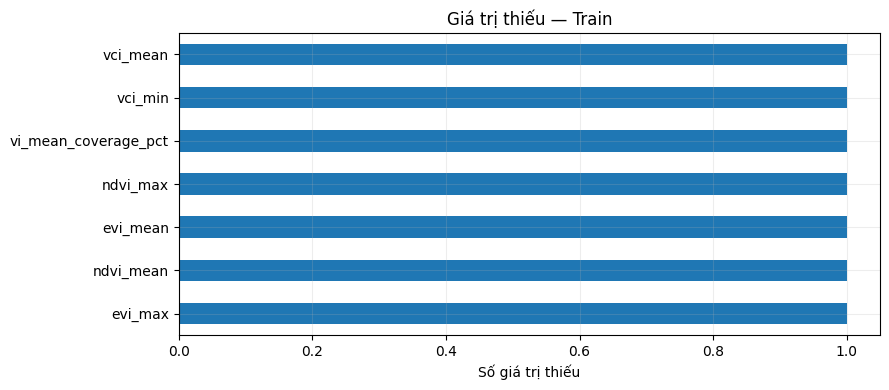

In [5]:
display(train_df[NUMERIC_FEATURES + [TARGET]].describe().T.round(3))
missing = train_df[FEATURES + [TARGET]].isna().sum().sort_values(ascending=False)
display(missing.to_frame('so_gia_tri_thieu_train'))
display(train_df.groupby('mua_vu')[TARGET].agg(['count', 'mean', 'std', 'min', 'max']).round(3))
if (missing > 0).any():
    fig, ax = plt.subplots(figsize=(9, 4))
    missing[missing > 0].sort_values().plot.barh(ax=ax)
    ax.set(xlabel='Số giá trị thiếu', title='Giá trị thiếu — Train')
    plt.tight_layout(); save_fig('01_gia_tri_thieu_train.png'); plt.show()

## 6. Phân phối và xu hướng trên Train

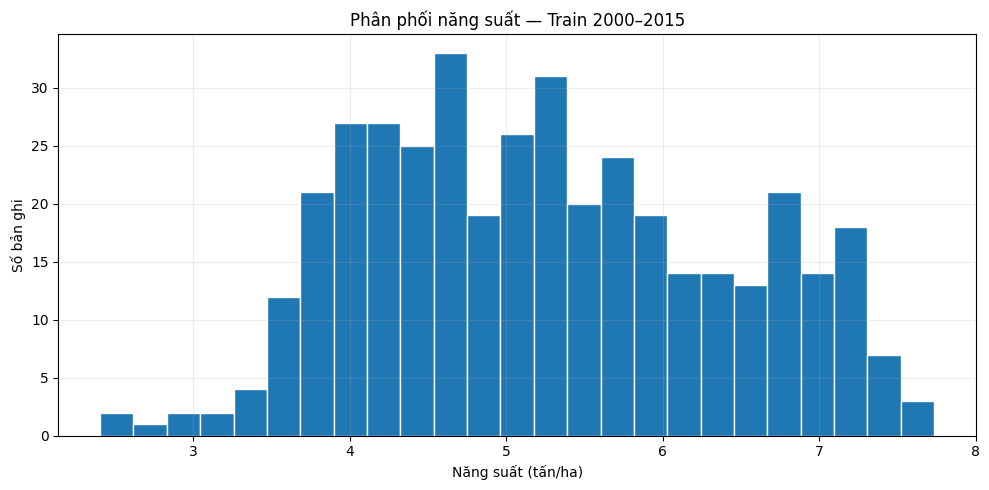

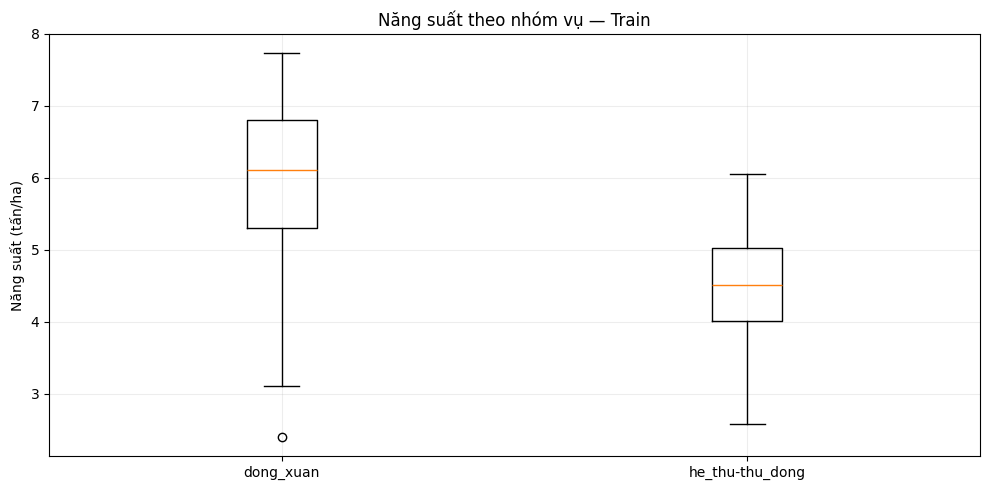

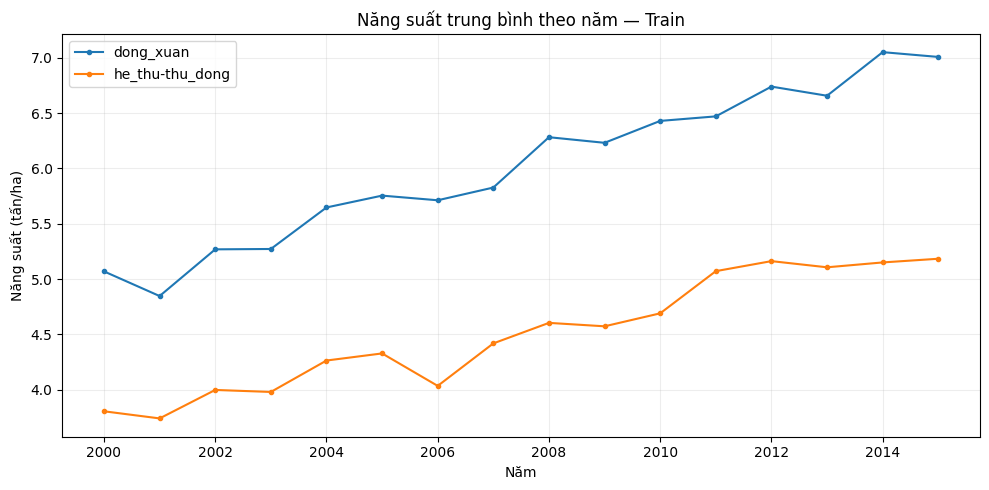

In [6]:
fig, ax = plt.subplots()
ax.hist(y_train, bins=25, edgecolor='white')
ax.set(title='Phân phối năng suất — Train 2000–2015', xlabel='Năng suất (tấn/ha)', ylabel='Số bản ghi')
plt.tight_layout(); save_fig('02_phan_phoi_train.png'); plt.show()

fig, ax = plt.subplots()
seasons = sorted(train_df['mua_vu'].unique())
ax.boxplot([train_df.loc[train_df['mua_vu'] == s, TARGET] for s in seasons], tick_labels=seasons)
ax.set(title='Năng suất theo nhóm vụ — Train', ylabel='Năng suất (tấn/ha)')
plt.tight_layout(); save_fig('03_nang_suat_theo_vu_train.png'); plt.show()

fig, ax = plt.subplots()
yearly = train_df.groupby(['nam', 'mua_vu'])[TARGET].mean().unstack()
for season in yearly.columns:
    ax.plot(yearly.index, yearly[season], marker='o', markersize=3, label=season)
ax.set(title='Năng suất trung bình theo năm — Train', xlabel='Năm', ylabel='Năng suất (tấn/ha)')
ax.legend(); plt.tight_layout(); save_fig('04_xu_huong_train.png'); plt.show()

## Ma trận tương quan và độ tương quan với nhãn

Chỉ tính tương quan trên Train để không dựa vào nhãn của Validation/Test khi diễn giải hoặc lựa chọn thuộc tính. Pearson mô tả quan hệ tuyến tính; Spearman mô tả quan hệ đơn điệu. Cả hai không suy ra quan hệ nhân quả. Các thuộc tính đồng biến theo năm có thể phản ánh xu thế chung.

MỨC ĐỘ TƯƠNG QUAN VỚI NHÃN (Train 2000–2015):


,pearson_r,spearman_rho,abs_pearson
rainfall_sum_mm,-0.647,-0.604,0.647
rainy_months_100mm,-0.623,-0.555,0.623
rainfall_max_month_mm,-0.554,-0.577,0.554
vi_months_available,-0.537,-0.636,0.537
nam,0.489,0.487,0.489
evi_max,0.456,0.450,0.456
evi_mean,0.437,0.479,0.437
vi_months_quality80,-0.421,-0.533,0.421
temperature_min_c,-0.376,-0.368,0.376
vci_mean,0.302,0.342,0.302


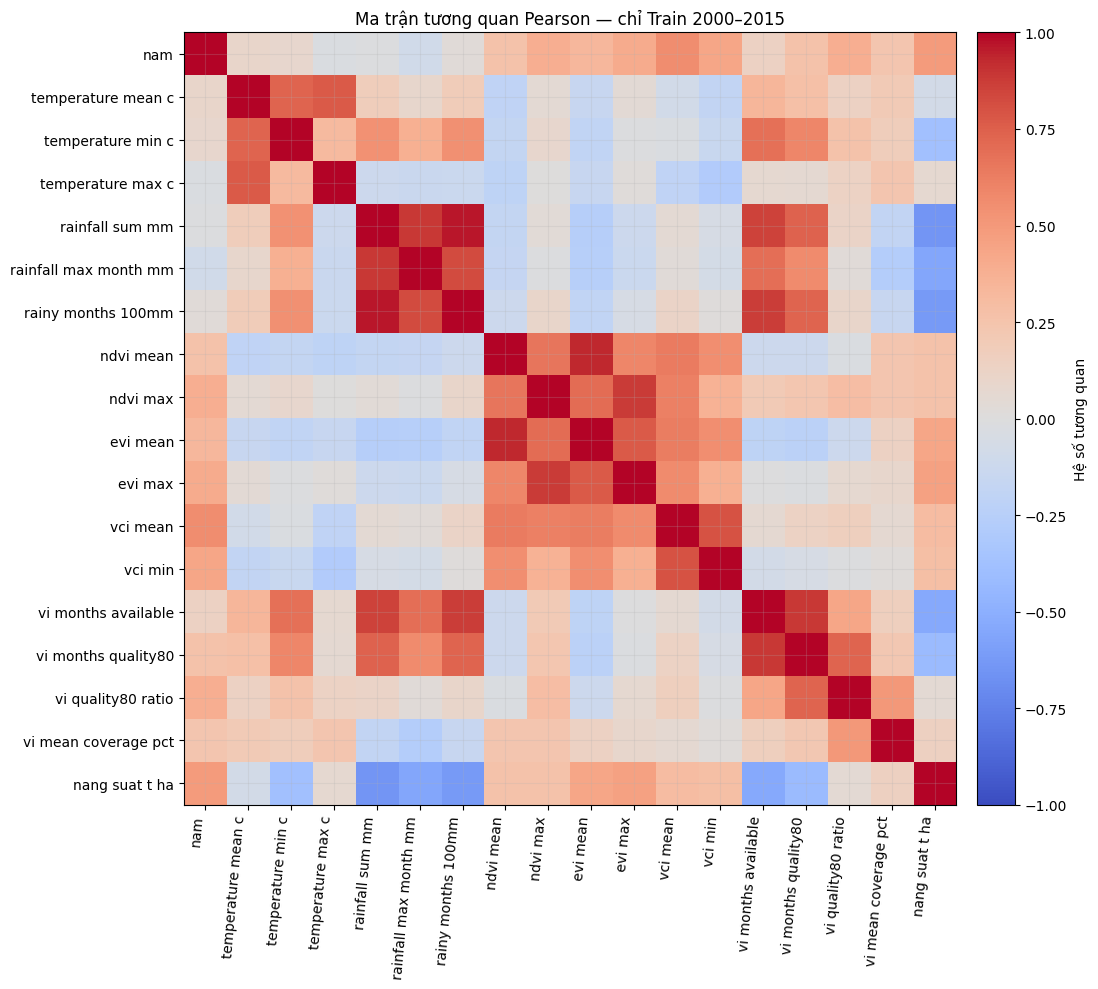

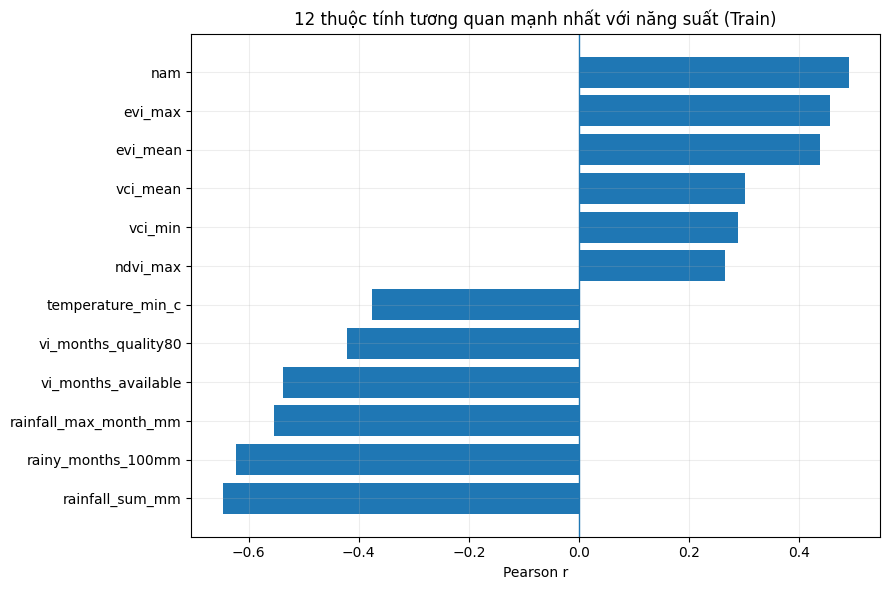

In [7]:
corr_features = NUMERIC_FEATURES + [TARGET]
pearson_matrix = train_df[corr_features].corr(method='pearson')
pearson_target = pearson_matrix[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
spearman_target = train_df[corr_features].corr(method='spearman')[TARGET].drop(TARGET)

corr_table = pd.DataFrame({
    'pearson_r': pearson_target,
    'spearman_rho': spearman_target.reindex(pearson_target.index),
    'abs_pearson': pearson_target.abs(),
}).round(3)
print('MỨC ĐỘ TƯƠNG QUAN VỚI NHÃN (Train 2000–2015):')
display(corr_table)

fig, ax = plt.subplots(figsize=(12, 10))
mat = ax.imshow(pearson_matrix, vmin=-1, vmax=1, cmap='coolwarm')
labels = [c.replace('_', ' ') for c in corr_features]
ax.set_xticks(range(len(labels)), labels=labels, rotation=85, ha='right')
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_title('Ma trận tương quan Pearson — chỉ Train 2000–2015')
fig.colorbar(mat, ax=ax, fraction=0.04, pad=0.02, label='Hệ số tương quan')
plt.tight_layout(); save_fig('05_ma_tran_tuong_quan.png'); plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
top = pearson_target.head(12).sort_values()
ax.barh(top.index, top.values)
ax.axvline(0, linewidth=1)
ax.set(xlabel='Pearson r', title='12 thuộc tính tương quan mạnh nhất với năng suất (Train)')
plt.tight_layout(); save_fig('06_tuong_quan_voi_nhan.png'); plt.show()

## Biểu đồ phân tán của các đặc trưng liên quan đến năng suất

Chọn 4 thuộc tính có |Pearson| lớn nhất trên tập Train. Đường thẳng chỉ là xu hướng tuyến tính, không chứng minh ảnh hưởng nhân quả.

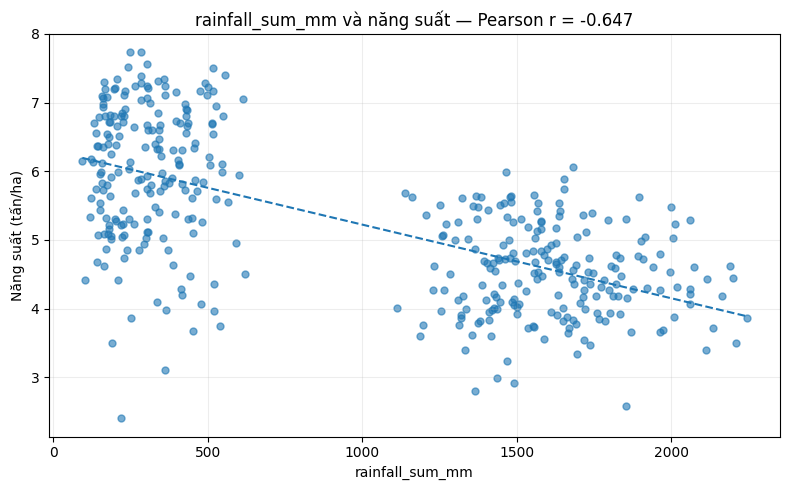

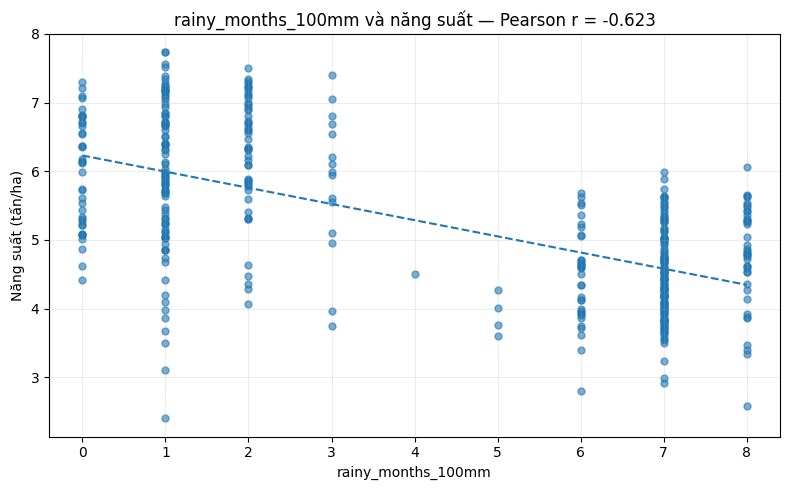

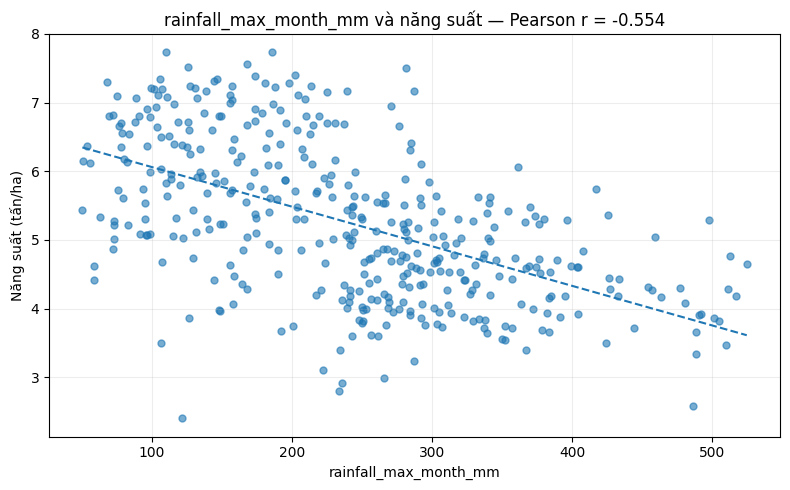

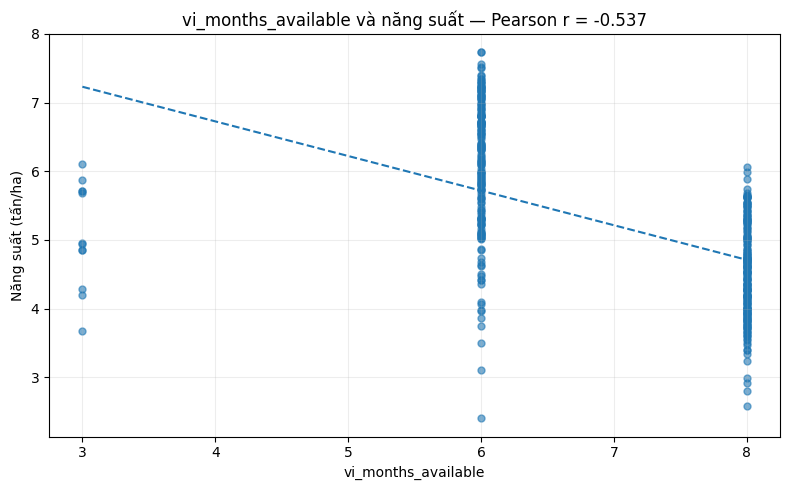

In [8]:
top4 = pearson_target.head(4).index.tolist()
for j, col in enumerate(top4, start=1):
    temp = train_df[[col, TARGET]].dropna()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(temp[col], temp[TARGET], alpha=0.6, s=25)
    if temp[col].nunique() > 1:
        m, b = np.polyfit(temp[col], temp[TARGET], 1)
        xx = np.linspace(temp[col].min(), temp[col].max(), 100)
        ax.plot(xx, m * xx + b, linestyle='--')
    ax.set(xlabel=col, ylabel='Năng suất (tấn/ha)',
           title=f'{col} và năng suất — Pearson r = {pearson_target[col]:.3f}')
    plt.tight_layout(); save_fig(f'07_scatter_{j}_{col}.png'); plt.show()

## 7. Tiền xử lý tối giản và hai mốc so sánh

CatBoost tự học ngưỡng chia và mã hóa phân loại **chỉ trên tập fit**. Các biến số giữ NaN (`nan_mode='Min'`); không StandardScaler, không OneHotEncoder và không điền giá trị từ Validation/Test.

Hai baseline cố định để kiểm tra mô hình có học thêm được gì:

1. Trung bình năng suất của lịch sử huấn luyện.
2. Trung bình theo tỉnh–vụ từ lịch sử huấn luyện; nếu gặp nhóm mới, dùng trung bình vụ rồi trung bình toàn bộ lịch sử.

Mô hình chính được định trước là CatBoost; baseline chỉ để so sánh, không tự đổi mô hình sau khi xem Test.

In [9]:
def evaluate(y_true, pred):
    pred = np.asarray(pred, dtype=float)
    if not np.isfinite(pred).all():
        raise ValueError('Dự đoán chứa NaN hoặc vô cực.')
    return {
        'MAE_t_ha': float(mean_absolute_error(y_true, pred)),
        'RMSE_t_ha': float(np.sqrt(mean_squared_error(y_true, pred))),
        'R2': float(r2_score(y_true, pred)),
    }

def baseline_predictions(history, future):
    overall = float(history[TARGET].mean())
    by_season = history.groupby('mua_vu')[TARGET].mean().to_dict()
    by_group = history.groupby(CATEGORICAL_FEATURES)[TARGET].mean().to_dict()
    group_pred = np.array([
        by_group.get((province, season), by_season.get(season, overall))
        for province, season in future[CATEGORICAL_FEATURES].itertuples(index=False, name=None)
    ])
    return {'Mean': np.full(len(future), overall), 'ProvinceSeasonMean': group_pred}

COMMON_PARAMS = dict(
    loss_function='RMSE', eval_metric='MAE',
    random_seed=RANDOM_STATE, thread_count=THREAD_COUNT, task_type='CPU',
    cat_features=CATEGORICAL_FEATURES, nan_mode='Min',
    has_time=True, boosting_type='Ordered',
    allow_writing_files=False, verbose=False,
)

def new_model(config, iterations):
    return CatBoostRegressor(**COMMON_PARAMS, **config, iterations=int(iterations))

print('Số đặc trưng:', len(FEATURES), '| Phân loại:', CATEGORICAL_FEATURES)
print('Không lọc biến theo nhãn Validation/Test; không K-Fold ngẫu nhiên.')

Số đặc trưng: 19 | Phân loại: ['adm1_code', 'mua_vu']
Không lọc biến theo nhãn Validation/Test; không K-Fold ngẫu nhiên.


## 8. Tìm kiếm 12 cấu hình trên Train → Validation

Mỗi cấu hình fit Train 2000–2015, dừng sớm bằng MAE trên Validation 2016–2018 (tối đa 1.500 vòng, patience 100). Chọn trước quy tắc: **MAE nhỏ nhất → RMSE nhỏ nhất → ít cây hơn → mã cấu hình**. Số cây tốt nhất cũng được chốt tại đây.

Validation đã tham gia chọn cấu hình và vòng lặp nên điểm số này có thiên lệch lựa chọn; không gọi đây là ước lượng độc lập. Không dùng các fold trước 2015 với VCI chuẩn 2000–2015. Test vẫn chưa được đưa vào fit/eval_set.

01/12 | MAE=0.4970 | cây=185


02/12 | MAE=0.4882 | cây=363


03/12 | MAE=0.4958 | cây=137


04/12 | MAE=0.4996 | cây=229


05/12 | MAE=0.4892 | cây=120


...

11/12 | MAE=0.4912 | cây=62


12/12 | MAE=0.4816 | cây=207


,candidate_id,depth,learning_rate,l2_leaf_reg,iterations,MAE_t_ha,RMSE_t_ha,R2,fit_seconds
0,9,6,0.03,3.0,131,0.4812,0.8788,0.4185,2.6283
1,12,6,0.06,10.0,207,0.4816,0.8760,0.4222,3.5936
2,8,5,0.06,10.0,177,0.4821,0.8889,0.4051,1.7933
3,6,5,0.03,10.0,378,0.4831,0.8795,0.4176,2.6821
4,7,5,0.06,3.0,58,0.4877,0.8982,0.3925,0.7191
5,2,4,0.03,10.0,363,0.4882,0.9007,0.3892,1.1031
6,10,6,0.03,10.0,413,0.4891,0.8816,0.4148,5.8436
7,5,5,0.03,3.0,120,0.4892,0.8956,0.3960,1.0848
8,11,6,0.06,3.0,62,0.4912,0.8996,0.3907,1.7330
9,3,4,0.06,3.0,137,0.4958,0.9069,0.3807,0.6706


,model,split,MAE_t_ha,RMSE_t_ha,R2
0,Mean,validation_2016_2018,0.9552,1.2439,-0.1650
1,ProvinceSeasonMean,validation_2016_2018,0.7013,0.9610,0.3047
2,CatBoost,validation_2016_2018,0.4812,0.8788,0.4185


CHỐT cấu hình trước Test: {'depth': 6, 'learning_rate': 0.03, 'l2_leaf_reg': 3.0} | số cây: 131


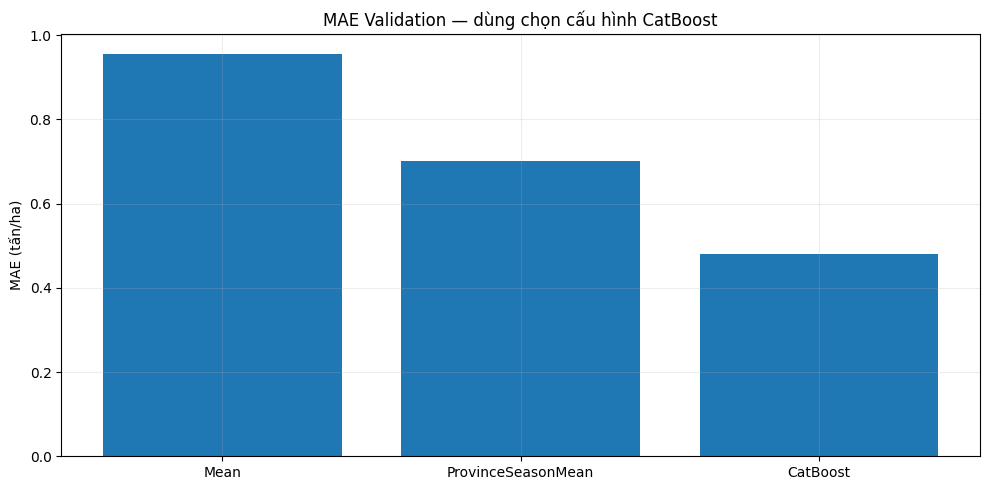

In [10]:
candidate_rows = []
best_model_on_train = None
best_key = None
BEST_CONFIG = None
BEST_ITERATIONS = None
for candidate_id, config in enumerate(SEARCH_CONFIGS, start=1):
    started = perf_counter()
    model = new_model(config, MAX_ITERATIONS)
    model.fit(X_train, y_train, eval_set=(X_val, y_val),
              early_stopping_rounds=EARLY_STOPPING_ROUNDS, use_best_model=True)
    prediction = model.predict(X_val)
    scores = evaluate(y_val, prediction)
    # CatBoost trả best_iteration từ 0, còn iterations là số lượng cây.
    n_trees = int(model.get_best_iteration() + 1)
    assert n_trees > 0 and n_trees == model.tree_count_
    row = {'candidate_id': candidate_id, **config, 'iterations': n_trees,
           **scores, 'fit_seconds': perf_counter() - started}
    candidate_rows.append(row)
    key = (scores['MAE_t_ha'], scores['RMSE_t_ha'], n_trees, candidate_id)
    if best_key is None or key < best_key:
        best_key = key
        best_model_on_train = model
        BEST_CONFIG = config.copy()
        BEST_ITERATIONS = n_trees
    print(f"{candidate_id:02d}/{len(SEARCH_CONFIGS)} | MAE={scores['MAE_t_ha']:.4f} | cây={n_trees}")

validation_candidates = pd.DataFrame(candidate_rows).sort_values(
    ['MAE_t_ha', 'RMSE_t_ha', 'iterations', 'candidate_id']).reset_index(drop=True)
BEST_CANDIDATE_ID = int(validation_candidates.iloc[0]['candidate_id'])
val_predictions = baseline_predictions(train_df, val_df)
val_predictions['CatBoost'] = best_model_on_train.predict(X_val)
validation_metrics = pd.DataFrame([
    {'model': name, 'split': 'validation_2016_2018', **evaluate(y_val, pred)}
    for name, pred in val_predictions.items()
])
display(validation_candidates.round(4))
display(validation_metrics.round(4))
print('CHỐT cấu hình trước Test:', BEST_CONFIG, '| số cây:', BEST_ITERATIONS)
if BEST_ITERATIONS == MAX_ITERATIONS:
    print('Cấu hình chọn đã chạm trần vòng lặp; giữ nguyên giới hạn tìm kiếm đã định trước.')

fig, ax = plt.subplots()
ax.bar(validation_metrics['model'], validation_metrics['MAE_t_ha'])
ax.set(title='MAE Validation — dùng chọn cấu hình CatBoost', ylabel='MAE (tấn/ha)')
plt.tight_layout(); save_fig('08_mae_validation.png'); plt.show()

## 9. Độ nhạy đặc trưng bằng hoán vị trên Validation

Giữ cố định CatBoost đã chọn, đo mức tăng MAE sau hoán vị từng cột (5 lần). Chỉ dùng để diễn giải; không dùng bảng này để tiếp tục loại biến hoặc điều chỉnh sau khi xem Test. Các biến tương quan có thể thay thế nhau, làm độ quan trọng thấp hoặc không ổn định; không suy ra quan hệ nhân quả. Validation đã được dùng chọn mô hình nên đây là phân tích thăm dò.

,feature,delta_MAE_t_ha,std_delta_MAE_t_ha
0,adm1_code,0.1946,0.0136
1,mua_vu,0.0245,0.0138
8,rainy_months_100mm,0.0136,0.0174
11,evi_mean,0.0093,0.0075
18,vi_mean_coverage_pct,0.0059,0.0014
10,ndvi_max,0.0043,0.0008
13,vci_mean,0.0043,0.0031
12,evi_max,0.0015,0.0051
14,vci_min,0.0015,0.0014
4,temperature_min_c,0.0008,0.0017


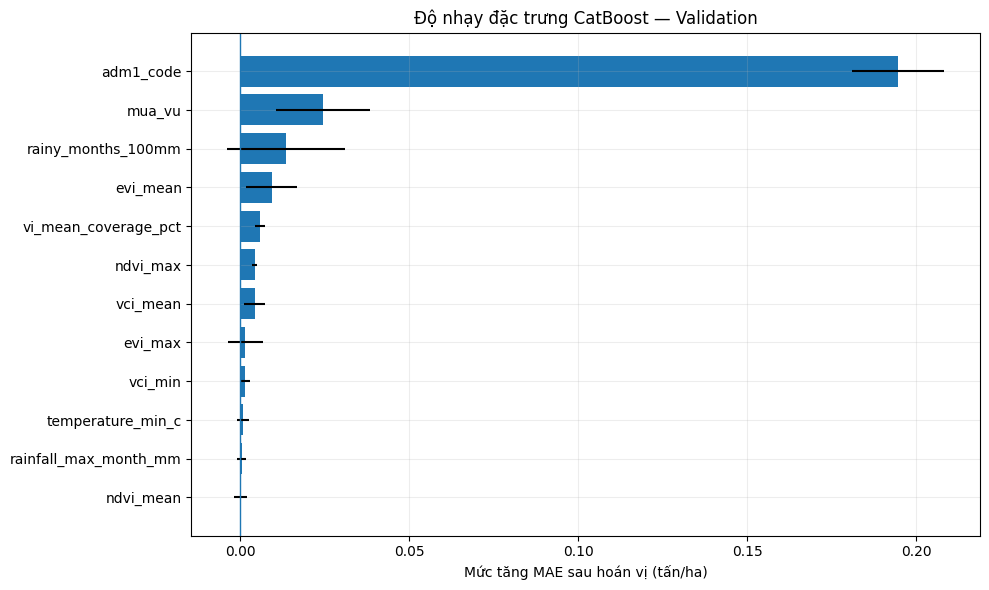

In [11]:
rng = np.random.default_rng(RANDOM_STATE)
baseline_val_mae = mean_absolute_error(y_val, val_predictions['CatBoost'])
importance_rows = []
for feature in FEATURES:
    deltas = []
    for _ in range(5):
        changed = X_val.copy()
        changed[feature] = rng.permutation(changed[feature].to_numpy())
        deltas.append(mean_absolute_error(y_val, best_model_on_train.predict(changed)) - baseline_val_mae)
    importance_rows.append({'feature': feature, 'delta_MAE_t_ha': float(np.mean(deltas)),
                            'std_delta_MAE_t_ha': float(np.std(deltas))})
importance_df = pd.DataFrame(importance_rows).sort_values('delta_MAE_t_ha', ascending=False)
display(importance_df.round(4))
fig, ax = plt.subplots(figsize=(10, 6))
imp_top = importance_df.head(12).sort_values('delta_MAE_t_ha')
ax.barh(imp_top['feature'], imp_top['delta_MAE_t_ha'], xerr=imp_top['std_delta_MAE_t_ha'])
ax.axvline(0, linewidth=1)
ax.set(title='Độ nhạy đặc trưng CatBoost — Validation', xlabel='Mức tăng MAE sau hoán vị (tấn/ha)')
plt.tight_layout(); save_fig('09_do_nhay_validation.png'); plt.show()

## 10. Huấn luyện cuối trên 2000–2018; đánh giá Test

Fit một CatBoost mới trên Train+Validation với cấu hình và số cây đã chốt. Không `eval_set`, không dừng sớm bằng Test. Cùng lúc tính hai baseline từ lịch sử 2000–2018. Đánh giá cả ba theo danh sách cố định; không đổi cấu hình hoặc mô hình theo bảng Test.

Đây là phép đánh giá sau khi fit đến 2018 và dự đoán đồng thời 2019–2022, không phải cập nhật mô hình hằng năm. R² có thể âm; luôn đọc cùng MAE/RMSE có đơn vị tấn/ha.

In [12]:
final_model = new_model(BEST_CONFIG, BEST_ITERATIONS)
final_model.fit(X_trainval, y_trainval)
assert final_model.tree_count_ == BEST_ITERATIONS

X_test, y_test = prepare_features(test_df), test_df[TARGET]
test_predictions = baseline_predictions(trainval_df, test_df)
test_predictions['CatBoost'] = final_model.predict(X_test)
test_metrics = pd.DataFrame([
    {'model': name, 'split': 'test_2019_2022', **evaluate(y_test, pred)}
    for name, pred in test_predictions.items()
])
metrics_all = pd.concat([validation_metrics, test_metrics], ignore_index=True)
selected_test = test_metrics.set_index('model').loc['CatBoost']
print('KẾT QUẢ TEST — mô hình chính đã định trước: CatBoost')
display(test_metrics.round(4))
print(f"CatBoost: MAE={selected_test['MAE_t_ha']:.4f} tấn/ha | "
      f"RMSE={selected_test['RMSE_t_ha']:.4f} tấn/ha | R²={selected_test['R2']:.4f}")

prediction_df = test_df[['adm1_code', 'tinh_thanh', 'nam', 'mua_vu']].copy()
prediction_df['actual_t_ha'] = y_test.to_numpy()
prediction_df['predicted_t_ha'] = test_predictions['CatBoost']
prediction_df['residual_t_ha'] = prediction_df['predicted_t_ha'] - prediction_df['actual_t_ha']
prediction_df['abs_error_t_ha'] = prediction_df['residual_t_ha'].abs()
for name in ['Mean', 'ProvinceSeasonMean']:
    prediction_df[f'prediction_{name}_t_ha'] = test_predictions[name]

group_rows = []
for field in ['nam', 'mua_vu', 'tinh_thanh']:
    for value, group in prediction_df.groupby(field):
        group_rows.append({'group_by': field, 'group': str(value), 'rows': len(group),
                           **evaluate(group['actual_t_ha'], group['predicted_t_ha'])})
group_metrics = pd.DataFrame(group_rows)
display(group_metrics.round(4))

KẾT QUẢ TEST — mô hình chính đã định trước: CatBoost


,model,split,MAE_t_ha,RMSE_t_ha,R2
0,Mean,test_2019_2022,1.0715,1.3604,-0.4002
1,ProvinceSeasonMean,test_2019_2022,0.9132,1.1223,0.0471
2,CatBoost,test_2019_2022,0.4724,0.7563,0.5672


CatBoost: MAE=0.4724 tấn/ha | RMSE=0.7563 tấn/ha | R²=0.5672


,group_by,group,rows,MAE_t_ha,RMSE_t_ha,R2
0,nam,2019,26,0.2791,0.3586,0.8244
1,nam,2020,26,0.7221,1.2557,0.3882
2,nam,2021,26,0.4728,0.5867,0.6187
3,nam,2022,26,0.4155,0.4883,0.7300
4,mua_vu,dong_xuan,52,0.5713,0.9733,0.3884
5,mua_vu,he_thu-thu_dong,52,0.3735,0.4434,0.4010
6,tinh_thanh,An Giang,8,0.5126,0.5368,0.4525
7,tinh_thanh,Bạc Liêu,8,0.6623,0.6841,0.3822
8,tinh_thanh,Bến Tre,8,0.9093,1.8577,-0.3443
9,tinh_thanh,Cà Mau,8,0.4975,0.6554,0.3550


## 11. Biểu đồ đánh giá cuối cùng

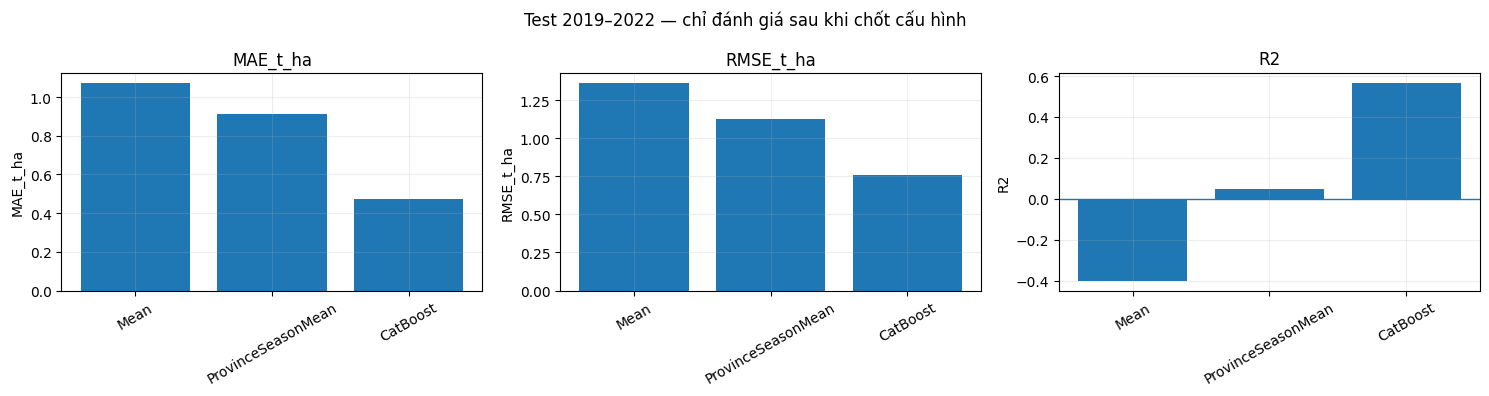

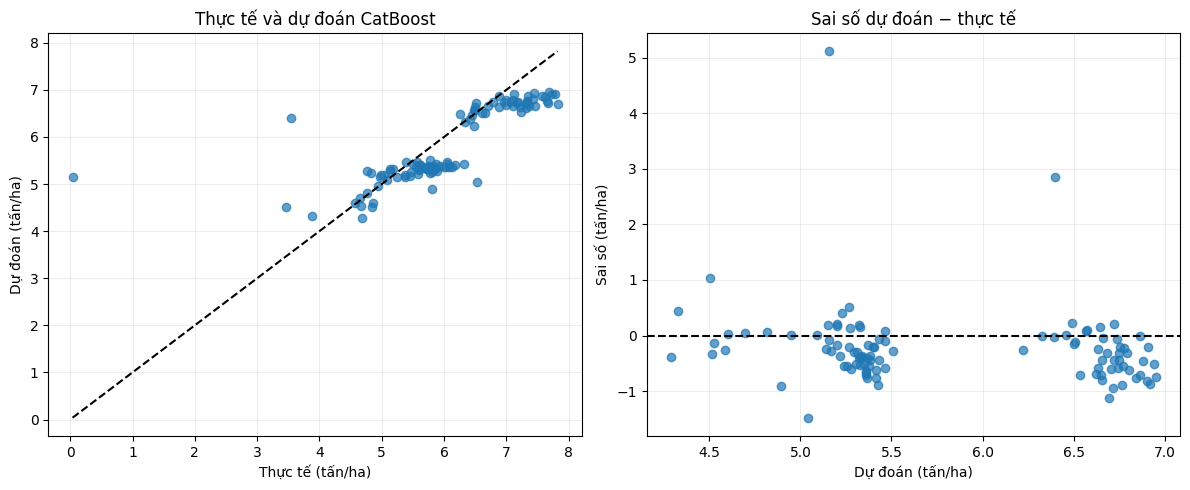

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ['MAE_t_ha', 'RMSE_t_ha', 'R2']):
    ax.bar(test_metrics['model'], test_metrics[metric])
    ax.set(title=metric, ylabel=metric)
    ax.tick_params(axis='x', labelrotation=30)
    if metric == 'R2':
        ax.axhline(0, linewidth=1)
fig.suptitle('Test 2019–2022 — chỉ đánh giá sau khi chốt cấu hình')
plt.tight_layout(); save_fig('10_chi_so_test.png'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, test_predictions['CatBoost'], alpha=0.7)
lo = min(y_test.min(), np.min(test_predictions['CatBoost']))
hi = max(y_test.max(), np.max(test_predictions['CatBoost']))
axes[0].plot([lo, hi], [lo, hi], linestyle='--', color='black')
axes[0].set(title='Thực tế và dự đoán CatBoost', xlabel='Thực tế (tấn/ha)', ylabel='Dự đoán (tấn/ha)')
axes[1].scatter(prediction_df['predicted_t_ha'], prediction_df['residual_t_ha'], alpha=0.7)
axes[1].axhline(0, linestyle='--', color='black')
axes[1].set(title='Sai số dự đoán − thực tế', xlabel='Dự đoán (tấn/ha)', ylabel='Sai số (tấn/ha)')
plt.tight_layout(); save_fig('11_du_doan_va_sai_so_test.png'); plt.show()

## 12. Xuất CSV, mô hình native và metadata tái lập

Lưu mô hình `.cbm` cùng JSON chứa thứ tự cột, quy tắc tiền xử lý, mốc chia, cấu hình chọn và SHA-256 của CSV. Thư mục `reports/catboost/` tách khỏi báo cáo ensemble cũ; các file cũ không mô tả lần chạy mới.

Bảng chỉ số ghi rõ Validation là tập chọn cấu hình. Khi báo cáo khoa học, dùng Test để mô tả hiệu năng cuối và nêu giới hạn về mặt nạ 2020, cửa sổ vụ, chuẩn VCI và dữ liệu có tương quan theo tỉnh/năm. Chưa có khoảng tin cậy hoặc kiểm định khả năng chuyển sang địa phương mới.

In [14]:
model_path = MODELS_DIR / 'rice_catboost_model.cbm'
metadata_path = MODELS_DIR / 'rice_catboost_metadata.json'
final_model.save_model(str(model_path))

metadata = {
    'model_type': 'CatBoostRegressor', 'target': TARGET, 'target_unit': 'tonne_per_hectare',
    'feature_names': FEATURES, 'preprocessing': PREPROCESSING,
    'common_params': COMMON_PARAMS, 'selected_config': BEST_CONFIG,
    'selected_candidate_id': BEST_CANDIDATE_ID, 'iterations': BEST_ITERATIONS,
    'selection_rule': 'validation_MAE_then_RMSE_then_tree_count_then_candidate_id',
    'search_configs': SEARCH_CONFIGS, 'max_iterations': MAX_ITERATIONS,
    'early_stopping_rounds': EARLY_STOPPING_ROUNDS, 'random_seed': RANDOM_STATE,
    'train_period': [2000, 2015], 'validation_period': [2016, 2018],
    'final_fit_period': [2000, 2018], 'test_period': [2019, 2022],
    'sort_keys': SORT_KEYS, 'validation_used_for_selection': True,
    'test_used_for_selection': False,
    'data_file': str(DATA_FILE.relative_to(PROJECT_ROOT)),
    'data_sha256': hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
    'data_rows': len(df), 'final_fit_rows': len(trainval_df),
    'window_policy': 'dong_xuan=Nov-Apr; he_thu-thu_dong=Apr-Nov (proxy)',
    'vci_baseline_years': [2000, 2015], 'rice_mask_year': 2020,
    'scope': 'retrospective_end_of_window_estimation_in_observed_provinces',
    'limitations': [
        'Static 2020 rice mask uses future spatial information for earlier years.',
        'VCI baseline 2000-2015 is unsuitable for forward validation before 2015.',
        'Full observation windows are required; not a pre-harvest forecast.',
        'No unseen-province validation or uncertainty interval.',
        'Validation scores include hyperparameter and iteration selection bias.',
    ],
    'versions': {'python': platform.python_version(), 'catboost': catboost.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__,
                 'sklearn': sklearn.__version__, 'matplotlib': matplotlib.__version__},
    'test_metrics': {key: float(selected_test[key]) for key in ['MAE_t_ha', 'RMSE_t_ha', 'R2']},
}
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
for table, filename in [
    (metrics_all, 'rice_model_metrics.csv'),
    (validation_candidates, 'rice_validation_candidates.csv'),
    (prediction_df, 'rice_test_predictions.csv'),
    (group_metrics, 'rice_test_metrics_by_group.csv'),
    (importance_df, 'rice_validation_permutation_importance.csv'),
    (corr_table, 'rice_train_correlations.csv'),
    (split_summary, 'rice_split_summary.csv'),
]:
    table.to_csv(REPORTS_DIR / filename, index=(filename == 'rice_train_correlations.csv'), encoding='utf-8-sig')
print('Đã lưu mô hình:', model_path)
print('Metadata:', metadata_path)
print('CSV và hình:', REPORTS_DIR)

Đã lưu mô hình: /workspace/rice_yield_estimation/models/catboost/rice_catboost_model.cbm
Metadata: /workspace/rice_yield_estimation/models/catboost/rice_catboost_metadata.json
CSV và hình: /workspace/rice_yield_estimation/reports/catboost


## 13. Nạp lại mô hình để suy luận

Dùng file `.cbm`, JSON và hàm `prepare_features` ở trên. Có thể truyền bảng CSV mới còn thiếu giá trị số/phân loại, nhưng phải có đủ cột; không truyền nhãn vào mô hình. Việc chuẩn hóa mã tỉnh giúp mã đọc dạng số nguyên hay số thực có cùng biểu diễn. Nhóm phân loại mới được CatBoost xử lý nội bộ; độ chính xác ở tỉnh mới chưa được đánh giá.

Dự đoán lại 5 dòng Test dưới đây chỉ kiểm tra lưu/nạp, không tính thêm một lần đánh giá để chọn mô hình.

In [15]:
loaded_metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
loaded_model = CatBoostRegressor()
loaded_model.load_model(str(model_path))

def predict_saved(frame):
    features = prepare_features(frame, loaded_metadata['feature_names'], loaded_metadata['preprocessing'])
    return loaded_model.predict(features)

reload_predictions = predict_saved(test_df.head(5))
np.testing.assert_allclose(reload_predictions, test_predictions['CatBoost'][:5], rtol=1e-12, atol=1e-12)
example = test_df[['adm1_code', 'tinh_thanh', 'nam', 'mua_vu']].head(5).copy()
example['predicted_t_ha'] = reload_predictions
display(example)
print('Kiểm tra lưu/nạp thành công; thứ tự cột và tiền xử lý giữ nhất quán.')

,adm1_code,tinh_thanh,nam,mua_vu,predicted_t_ha
0,3326,An Giang,2019,dong_xuan,6.791961
1,3330,Bạc Liêu,2019,dong_xuan,6.657814
2,3332,Bến Tre,2019,dong_xuan,5.229075
3,3339,Cà Mau,2019,dong_xuan,5.466789
4,3343,Đồng Tháp,2019,dong_xuan,6.682859


Kiểm tra lưu/nạp thành công; thứ tự cột và tiền xử lý giữ nhất quán.
